#**DATA DIRI :**
#**NAMA : GILBERTO PATRICK LIE**
#**ID COHORT : M891D5Y0695**
#**LEARNING PATH : MACHINE LEARNING**

# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**: Kaggle

   **Link Dataset**: https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification
  
   **Informasi mengenai Dataset**: Dataset ini memiliki 10.000 record atau baris dan sepuluh fitur yang berkaitan atau relevan dengan kondisi dari sebuah mesin, kesepuluh fitur yang ada pada dataset ini yaitu :
   - UDI = Identifier unik
   - Product ID = Id dari produk
   - Type = Tipe dari mesin (Low/Medium/High)
   - Air Temperature (dalam satuan kelvin) = Temperatur suhu dari udara
   - Process temperature (dalam satuan kelvin) = Temperatur suhu ketika proses
   - Rotational Speed (dalam satuan rpm) = Kecepatan kipas berputar
   - Torque = Besarnya gaya torsi
   - Tool Wear (dalam satuan menit) = Berapa lama mesin dipakai
   - Target (binary) = Target binary (0 tidak ada failure, 1 ada failure)
   - Failure Type (multiclass binary) = Jenis failure yang terjadi

   Tujuan dari dataset ini adalah untuk dijadikan bahan untuk melatih model yang dapat menentukan apakah sebuah mesin membutuhkan maintenance atau tidak (1 jika terdapat failure, 0 jika tidak terdapat failure).

   Saya memilih dataset ini karena saya merasa dataset ini memiliki data yang saya perlukan untuk mengembangkan model yang dapat menyelesaikan permasalahan asli atau real life problems.

# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [ ]:
df = pd.read_csv('predictive_maintenance_raw.csv')

In [ ]:
df.shape

(10000, 10)

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [ ]:
df = df.drop(columns=['UDI', 'Product ID', 'Failure Type'])

In [ ]:
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

Index(['Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target'],
      dtype='object')


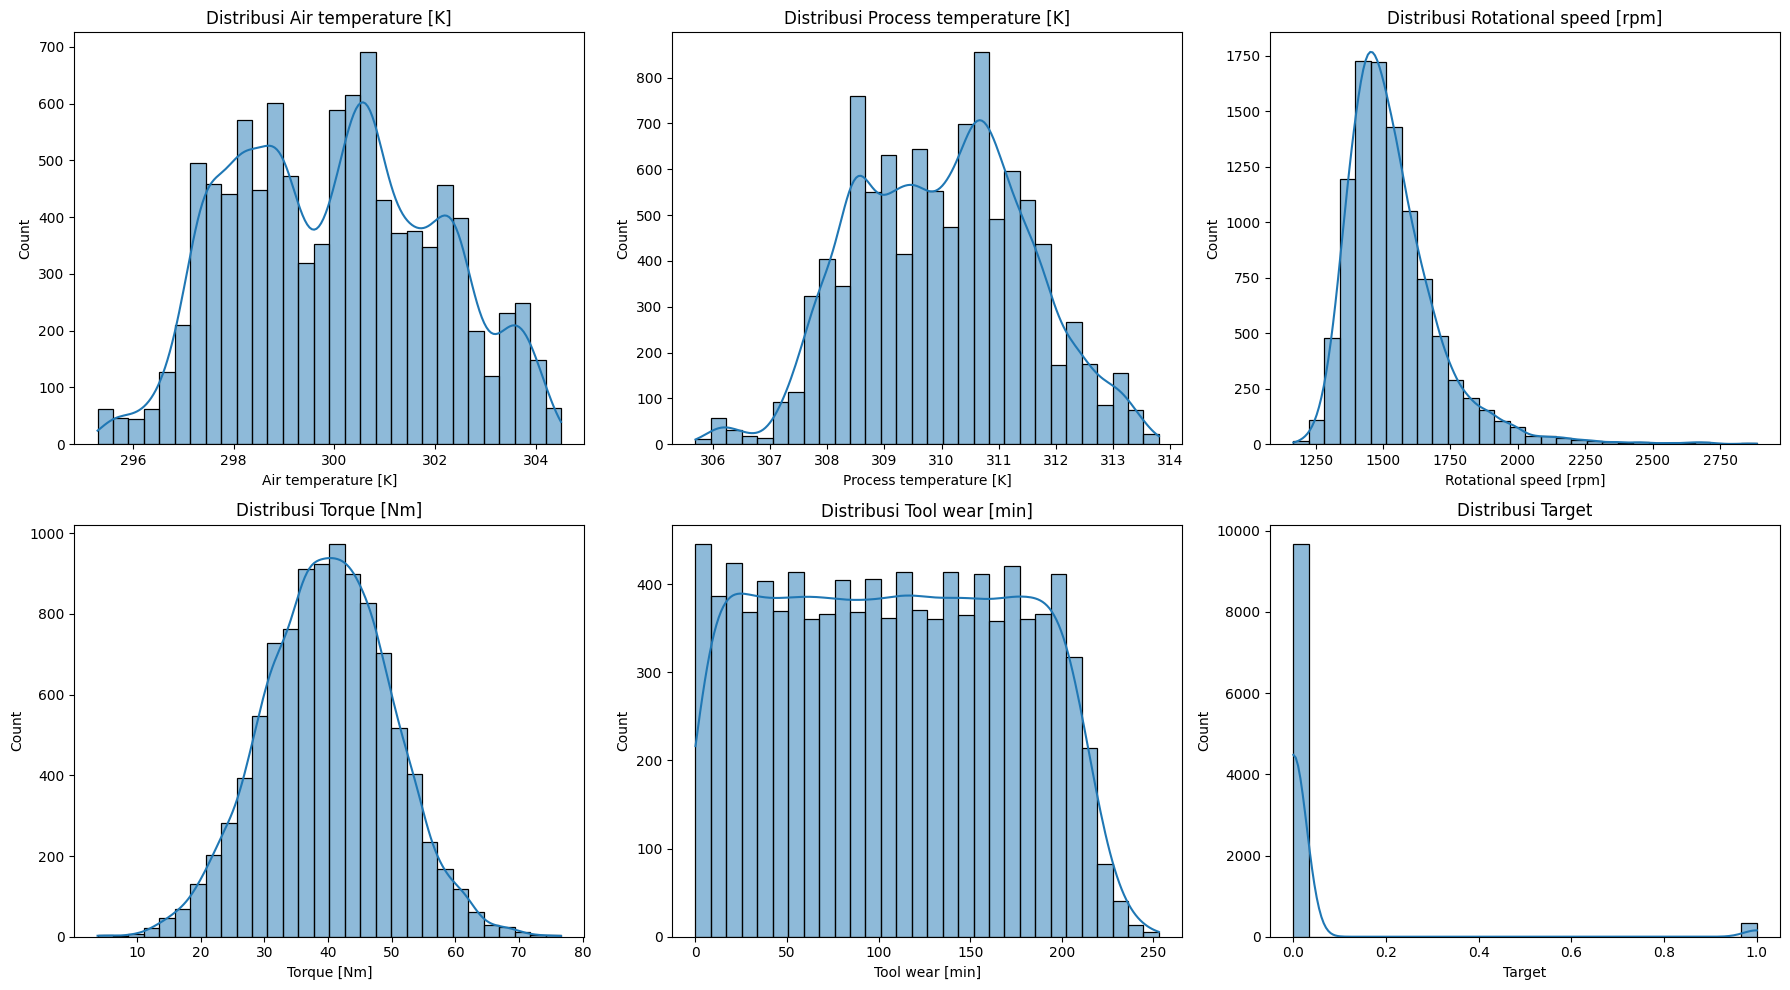

In [ ]:
numerical_col = df.select_dtypes(include=['number'])
print(numerical_col.columns)

n_cols = 3
n_rows = (len(numerical_col.columns) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, column in enumerate(numerical_col):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=30,
        ax=axes[i]
    )
    axes[i].set_title(f'Distribusi {column}', fontsize=12)
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Count')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


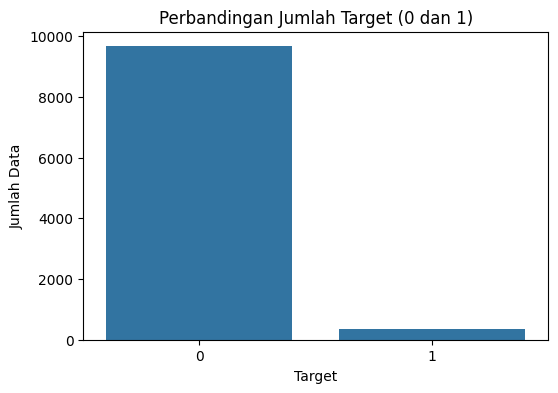

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(
    data=df,
    x='Target'
)

plt.title('Perbandingan Jumlah Target (0 dan 1)')
plt.xlabel('Target')
plt.ylabel('Jumlah Data')
plt.show()

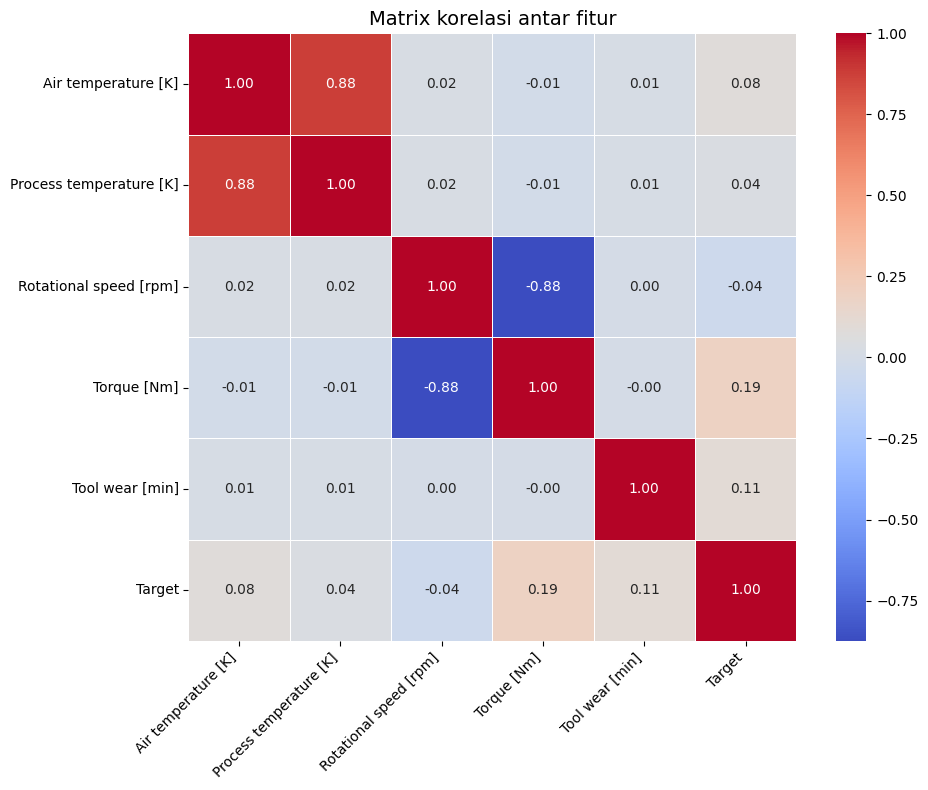

In [ ]:
corr_matrix = df.select_dtypes(include=['number']).corr()

plt.figure(figsize=(10,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=True
)

plt.title('Matrix korelasi antar fitur', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

In [ ]:
df.isnull().sum()

,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Target,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#Saya mengubah temperature dari satuan Kelvin menjadi Celsius agar lebih mudah saya pahami karena saya menggunakan satuan celsius.
df['Air temperature [K]'] = df['Air temperature [K]'] - 273.15
df['Process temperature [K]'] = df['Process temperature [K]'] - 273.15

df.rename(columns={
    'Air temperature [K]': 'Air temperature [C]',
    'Process temperature [K]': 'Process temperature [C]'
}, inplace=True)

df.head()

,Type,Air temperature [C],Process temperature [C],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
0,M,24.95,35.45,1551,42.8,0,0
1,L,25.05,35.55,1408,46.3,3,0
2,L,24.95,35.35,1498,49.4,5,0
3,L,25.05,35.45,1433,39.5,7,0
4,L,25.05,35.55,1408,40.0,9,0


In [ ]:
#Saya lakukan encoding one hot pada kolom atau fitur Type dengan tujuan mengubah kolom Type dari kategorikal menjadi numerik agar bisa digunakan sebagai input untuk model
type_col = pd.get_dummies(
    df['Type'],
    prefix='Type',
    drop_first=True,
    dtype=int
)

df = pd.concat(
    [df.drop(columns='Type'), type_col],
    axis=1
)

In [ ]:
#Karena encoding OneHot menghasilkan kolom baru, mengakibatkan kolom target tidak berada diujung kanan.
#Sehingga saya tuliskan kode dibawah supaya kolom target berada dikanan tanpa mengubah valuenya (hanya untuk tampilan saja agar terlihat lebih baik).
df['Target_kanan'] = df['Target']
df.drop(columns=['Target'], inplace=True)
df.rename(columns={'Target_kanan': 'Target'}, inplace=True)
df.head()

,Air temperature [C],Process temperature [C],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M,Target
0,24.95,35.45,1551,42.8,0,0,1,0
1,25.05,35.55,1408,46.3,3,1,0,0
2,24.95,35.35,1498,49.4,5,1,0,0
3,25.05,35.45,1433,39.5,7,1,0,0
4,25.05,35.55,1408,40.0,9,1,0,0


Balancing Data (karena data target antara 0 dan 1 sangat imbalance)

In [ ]:
X = df.drop(columns=['Target'])
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train
)

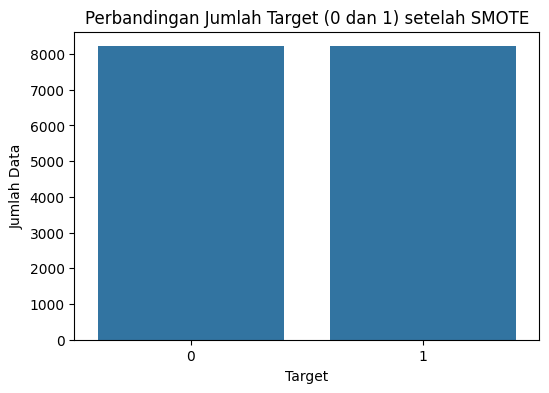

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x=y_train_balanced)

plt.title('Perbandingan Jumlah Target (0 dan 1) setelah SMOTE')
plt.xlabel('Target')
plt.ylabel('Jumlah Data')
plt.show()

In [ ]:
X_train_balanced_df = pd.DataFrame(
    X_train_balanced,
    columns=X_train.columns
)

y_train_balanced_df = pd.DataFrame(
    y_train_balanced,
    columns=['Target']
)

In [ ]:
train_df = pd.concat(
    [X_train_balanced_df, y_train_balanced_df],
    axis=1
)

In [ ]:
train_df.shape
train_df['Target'].value_counts()

,count
Target,
0,8212
1,8212


Save train dataset

In [ ]:
train_df.head()

,Air temperature [C],Process temperature [C],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M,Target
0,1.649453,0.942881,0.851478,-1.213282,-0.826983,-1.232282,-0.650988,0
1,0.699253,0.672753,-0.294402,-0.351262,-0.261020,-1.232282,1.536126,0
2,1.149348,0.942881,-0.333340,0.560876,-0.764098,-1.232282,1.536126,0
3,1.199359,0.672753,0.089412,0.059701,1.531196,0.811503,-0.650988,0
4,-1.451200,-1.218141,-1.067594,1.082097,-0.921310,0.811503,-0.650988,0


In [ ]:
train_df.to_csv('train_predictive_maintenance_preprocessed.csv', index=False)

Save test dataset

In [ ]:
X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns
)

test_df = pd.concat(
    [X_test_scaled_df, y_test.reset_index(drop=True)],
    axis=1
)

In [ ]:
test_df.to_csv('test_predictive_maintenance_preprocessed.csv', index=False)